<a href="https://colab.research.google.com/github/FALAA-1285/Pembelajaran-Mesin-2026/blob/main/Pertemuan%205/Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Soal 1 – Pilih salah satu dataset nyata dari `sklearn.datasets`

Dataset yang dipilih adalah **iris dataset** (150 data, 4 fitur, 3 label asli).

**Langkah 0 – Persiapan Lingkungan**

In [1]:
# Instalasi library hdbscan (tidak tersedia default di sklearn)
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
import hdbscan

**Langkah 1 – Load Dataset**

In [2]:
iris = load_iris()
X = iris.data
labels_true = iris.target

print('Jumlah data :', X.shape[0])
print('Jumlah fitur:', X.shape[1])
print('Label asli  :', set(labels_true))

Jumlah data : 150
Jumlah fitur: 4
Label asli  : {np.int64(0), np.int64(1), np.int64(2)}


### Soal 2 – Lakukan clustering dengan HDBSCAN

In [3]:
hdb = hdbscan.HDBSCAN(min_cluster_size=5).fit(X)
labels = hdb.labels_

### Soal 3 – Laporkan hasil

**Jumlah cluster dan banyaknya noise**

In [4]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print('Jumlah cluster:', n_clusters)
print('Banyaknya noise:', n_noise)

Jumlah cluster: 2
Banyaknya noise: 0


**Visualisasi dengan PCA (reduksi 4 dimensi menjadi 2 dimensi)**

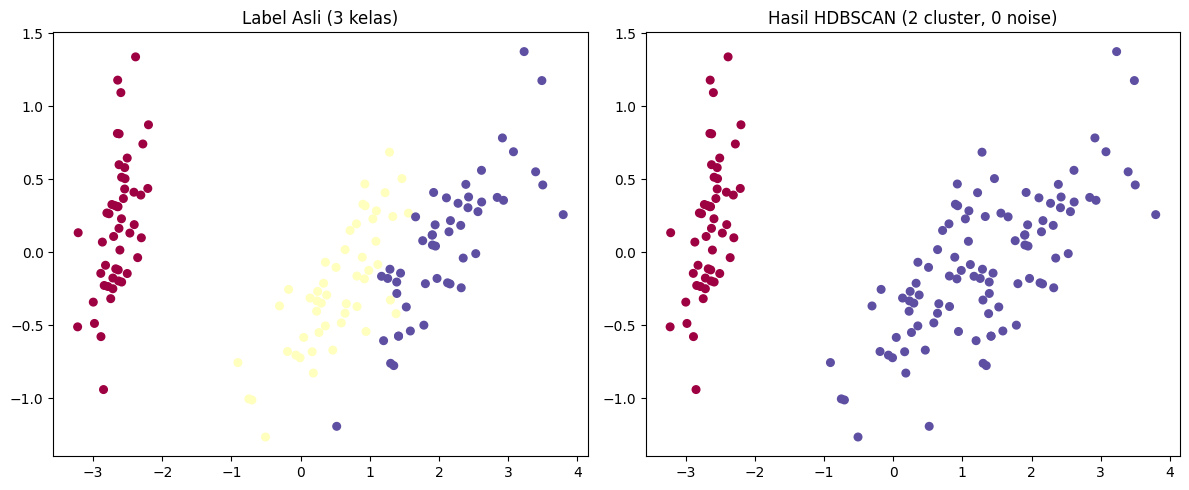

In [5]:
# Reduksi dimensi dengan PCA
X_pca = PCA(n_components=2).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Label asli
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_true, cmap='Spectral', s=30)
axes[0].set_title('Label Asli (3 kelas)')

# Hasil HDBSCAN
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='Spectral', s=30)
axes[1].scatter(X_pca[labels == -1, 0], X_pca[labels == -1, 1], c='black', marker='x', s=30)
axes[1].set_title(f'Hasil HDBSCAN ({n_clusters} cluster, {n_noise} noise)')

plt.tight_layout()
plt.show()

### Soal 4 – Analisis singkat: apakah hasil HDBSCAN sesuai dengan label asli?

**Evaluasi dengan metrik**

In [6]:
from sklearn import metrics

print('Homogeneity :', round(metrics.homogeneity_score(labels_true, labels), 3))
print('Completeness:', round(metrics.completeness_score(labels_true, labels), 3))
print('V-measure   :', round(metrics.v_measure_score(labels_true, labels), 3))
print('ARI         :', round(metrics.adjusted_rand_score(labels_true, labels), 3))
print('AMI         :', round(metrics.adjusted_mutual_info_score(labels_true, labels), 3))

Homogeneity : 0.579
Completeness: 1.0
V-measure   : 0.734
ARI         : 0.568
AMI         : 0.732


**Analisis**

Hasil clustering HDBSCAN **belum sepenuhnya sesuai** dengan label asli dataset iris.

1. HDBSCAN hanya membentuk **2 cluster**, sedangkan label asli iris memiliki **3 kelas** (setosa, versicolor, virginica). Noise yang terdeteksi sebanyak **0 data**.
2. Pada visualisasi PCA terlihat kelas *setosa* terpisah jelas dari dua kelas lainnya, sedangkan *versicolor* dan *virginica* saling berdempetan. Karena kedua kelas tersebut berada pada satu wilayah dengan kepadatan yang menyambung, HDBSCAN menganggapnya sebagai satu cluster.
3. Nilai **Completeness = 1.0** menunjukkan setiap kelas asli tidak terpecah ke beberapa cluster, tetapi **Homogeneity hanya 0.579** karena ada satu cluster yang berisi dua kelas sekaligus. Akibatnya nilai **V-measure = 0.734**, **ARI = 0.568**, dan **AMI = 0.732**.

**Kesimpulan:** HDBSCAN berhasil memisahkan kelas yang kepadatannya benar-benar terpisah (setosa), namun tidak dapat memisahkan versicolor dan virginica yang saling tumpang tindih. Hal ini wajar karena HDBSCAN bekerja berdasarkan kepadatan data, bukan berdasarkan label.